# Week 8 Lab: get your own data from an API

From this week you build **one project**, adding a layer each week. By Week 12 it has users who log in,
a database, a Streamlit dashboard and an AI assistant, all working on data you fetched yourself.

| Week | You add |
|---|---|
| 8 | get data from an API and save it as a CSV file |
| 9 | register and log in (passwords hashed with bcrypt) |
| 10 | a SQLite database, and the code split into a package |
| 11 | a Streamlit dashboard with a login page |
| 12 | an AI assistant |

All of it lives in **one GitHub repository called `CST1510_CW2`**. You commit to it at the end of every lab,
so by Week 12 the repository holds the whole project and its history.

By the end of today it contains:

```
CST1510_CW2/
  fetch_data.py       gets the data from the API
  DATA/raw.csv        the data, saved by fetch_data.py
  .gitignore          files Git must not upload
```

Each step is: a short idea, something to **Try**, then (at the end) the file to **Build**.
A finished example is in `DEMO/project/` (it uses earthquakes). It shows what your `CST1510_CW2` folder looks like.

In [ ]:
# Run this cell first, every time you open the notebook.
import sys
from pathlib import Path

# Your project lives in the CST1510_CW2 folder. This notebook looks for it in the usual places.
# If it cannot find it, paste the full path between the quotes, for example "C:/Users/sam/Documents/CST1510_CW2"
MY_FOLDER = ""


def find_project():
    if MY_FOLDER:
        return Path(MY_FOLDER)
    here = Path.cwd()
    for folder in [here, *here.parents]:
        if folder.name == "CST1510_CW2":
            return folder
    for base in [Path.home(), Path.home() / "Documents", Path.home() / "Desktop", Path.home() / "OneDrive" / "Documents"]:
        if (base / "CST1510_CW2").exists():
            return base / "CST1510_CW2"
    return here


PROJECT = find_project()
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
print("Project folder:", PROJECT)
if PROJECT.name != "CST1510_CW2":
    print("\nI could not find your CST1510_CW2 folder. Paste its full path into MY_FOLDER above, then run this cell again.")


def show_checks(checks):
    """Print PASS or FAIL for each (passed, description) pair."""
    for passed, description in checks:
        print("PASS" if passed else "FAIL", "-", description)
    print("\nAll checks passed." if all(p for p, _ in checks) else "\nFix the lines marked FAIL, save, and run again.")


print("Project folder:", PROJECT)

## Step 0: Set up your repository (once)

Do the section **Week 8 (CW2): your project repository** of the Setup Guide on the course website. In short:

1. Create an empty GitHub repository called `CST1510_CW2` and clone it (`git clone https://github.com/YOUR-USERNAME/CST1510_CW2.git`).
2. Open that folder in VS Code (*File > Open Folder*) and use its terminal.
3. Create a virtual environment there and install the libraries from the course file:
   `python -m venv .venv`, activate it, then
   `python -m pip install -r "../CST1510/Week 00 - Orientation and Setup/requirements.txt"`
   (`python3` on Mac and Linux). In this notebook choose *Select Kernel* and pick that same `.venv`.
4. Add a `.gitignore` file with the lines in the guide. They keep your users, database and API key off GitHub:

```
.venv/
__pycache__/
.ipynb_checkpoints/
.pytest_cache/
.DS_Store
.env
DATA/app.db
DATA/users.txt
.streamlit/secrets.toml
practice/
```

This is a **different** `.gitignore` from the one in your `CST1510` repository (Weeks 1 to 7). That one uploads only your LAB folders. This one
uploads **everything except** the private files above, because here the whole project is what you hand in.

This notebook is only your step-by-step instructions. Keep it wherever you like: it is **not** part of the project and it does not go to GitHub.
Only the project files do.

Run the cell below to check.

In [ ]:
print("Working folder:", PROJECT.name)
gitignore = PROJECT / ".gitignore"
text = gitignore.read_text() if gitignore.exists() else ""
show_checks([
    ((PROJECT / ".git").exists(), "this folder is a Git repository (cloned from GitHub)"),
    (PROJECT.name == "CST1510_CW2", f"the folder is called CST1510_CW2 (it is called {PROJECT.name})"),
    ("DATA/users.txt" in text and "secrets.toml" in text, ".gitignore has the private-file lines"),
])

## Step 1: Choose your API

An **API** is a web address that sends back data instead of a web page.
Pick one of these. They are free and need no key.

| Area | Data | `URL` | `PARAMS` | `RECORDS_KEY` |
|---|---|---|---|---|
| Science / Geography | Earthquakes (the demo) | `https://earthquake.usgs.gov/fdsnws/event/1/query` | `{"format": "geojson", "minmagnitude": 2.5, "limit": 500}` | `"features"` |
| Health | COVID-19 by country | `https://disease.sh/v3/covid-19/countries` | `{}` | `None` |
| Computing / IT | GitHub repositories of an organisation | `https://api.github.com/orgs/python/repos` | `{"per_page": 100}` | `None` |

Want a different API? Ask your tutor first. It needs at least 50 records, one **number** column and one **text** column
that you can group by (a category, a country, a type...).

Write down your choice. You will use its three values in the next steps.

**My choice:** Computing / IT, GitHub repositories of the `python` organisation.

- `URL` = `https://api.github.com/orgs/python/repos`
- `PARAMS` = `{"per_page": 100}`
- `RECORDS_KEY` = `None` (the reply is already a list)

## Step 2: Ask the API for data

`requests.get(url, params=...)` sends the request. The **status code** says what happened:
`200` worked, `404` that address does not exist.

**Try it.** Run this, then change `URL` and `PARAMS` to your own choice and run it again until you get `200`.

In [2]:
import requests

URL = "https://api.github.com/orgs/python/repos"     # <- CHANGE to your choice from Step 1
PARAMS = {"per_page": 100}                           # <- and its params

response = requests.get(URL, params=PARAMS, timeout=15)
print("Status:", response.status_code)
print(response.text[:300])

Status: 200
[{"id":2474719,"node_id":"MDEwOlJlcG9zaXRvcnkyNDc0NzE5","name":"getpython3.com","full_name":"python/getpython3.com","private":false,"owner":{"login":"python","id":1525981,"node_id":"MDEyOk9yZ2FuaXphdGlvbjE1MjU5ODE=","avatar_url":"https://avatars.githubusercontent.com/u/1525981?v=4","gravatar_id":"",


### What is JSON?

The reply starts with `{` or `[`: that is **JSON** (JavaScript Object Notation), the plain-text format almost every API uses to send data.
It is only text, but it is written to look like Python:

| JSON text | Python, after `.json()` |
|---|---|
| `{"name": "Rex", "age": 4}` (an *object*) | a dictionary |
| `["dog", "cat"]` (an *array*) | a list |
| `true` / `false` / `null` | `True` / `False` / `None` |

Text is always in **double** quotes. Values can be nested: an object inside an object, or a **list of objects**, which is just a table of records.
`response.json()` turns the reply text into real Python dictionaries and lists. Here is the idea on a tiny example:

In [3]:
import json

text = '{"name": "Rex", "age": 4, "vaccinated": true, "tags": ["dog", "friendly"]}'
pet = json.loads(text)          # this is what response.json() does for you
print(type(pet), pet["name"], pet["vaccinated"], pet["tags"][0])

<class 'dict'> Rex True dog


## Step 3: Find the list of records

A reply is either a **list** of records, or a **dictionary** with the list inside it under some key.
That key is your `RECORDS_KEY` (use `None` when the reply is already a list).

**Try it.** Run this on your own reply:

In [4]:
data = response.json()
print("Type:", type(data))
if isinstance(data, dict):
    print("Keys:", list(data.keys()))      # which key holds the list?
else:
    print("It is already a list of", len(data), "records")

Type: <class 'list'>
It is already a list of 99 records


Earthquakes come back as a dictionary, and the list is under `"features"`. COVID-19 and GitHub are already lists.

## Step 4: Make a table with pandas

`pd.json_normalize()` turns a list of records into a table. Records that contain other records are flattened:
`{"properties": {"mag": 5}}` becomes a column `properties_mag`.

**Try it:**

In [5]:
import pandas as pd

RECORDS_KEY = None          # <- CHANGE to your key from Step 3 (for example "features")

records = data[RECORDS_KEY] if RECORDS_KEY else data
table = pd.json_normalize(records, sep="_")
print(table.shape, "(rows, columns)")
print(list(table.columns))
table.head()

(99, 109) (rows, columns)
['id', 'node_id', 'name', 'full_name', 'private', 'html_url', 'description', 'fork', 'url', 'forks_url', 'keys_url', 'collaborators_url', 'teams_url', 'hooks_url', 'issue_events_url', 'events_url', 'assignees_url', 'branches_url', 'tags_url', 'blobs_url', 'git_tags_url', 'git_refs_url', 'trees_url', 'statuses_url', 'languages_url', 'stargazers_url', 'contributors_url', 'subscribers_url', 'subscription_url', 'commits_url', 'git_commits_url', 'comments_url', 'issue_comment_url', 'contents_url', 'compare_url', 'merges_url', 'archive_url', 'downloads_url', 'issues_url', 'pulls_url', 'milestones_url', 'notifications_url', 'labels_url', 'releases_url', 'deployments_url', 'created_at', 'updated_at', 'pushed_at', 'git_url', 'ssh_url', 'clone_url', 'svn_url', 'homepage', 'size', 'stargazers_count', 'watchers_count', 'language', 'has_issues', 'has_projects', 'has_downloads', 'has_wiki', 'has_pages', 'has_discussions', 'forks_count', 'mirror_url', 'archived', 'disabled',

,id,node_id,name,full_name,private,html_url,description,fork,url,forks_url,...,permissions_admin,permissions_maintain,permissions_push,permissions_triage,permissions_pull,license_key,license_name,license_spdx_id,license_url,license_node_id
0,2474719,MDEwOlJlcG9zaXRvcnkyNDc0NzE5,getpython3.com,python/getpython3.com,False,https://github.com/python/getpython3.com,getpython3.com page and resources.,False,https://api.github.com/repos/python/getpython3...,https://api.github.com/repos/python/getpython3...,...,False,False,False,False,True,NaN,NaN,NaN,NaN,NaN
1,3698918,MDEwOlJlcG9zaXRvcnkzNjk4OTE4,community-starter-kit,python/community-starter-kit,False,https://github.com/python/community-starter-kit,Collection of resources for Python community o...,False,https://api.github.com/repos/python/community-...,https://api.github.com/repos/python/community-...,...,False,False,False,False,True,NaN,NaN,NaN,NaN,NaN
2,4241382,MDEwOlJlcG9zaXRvcnk0MjQxMzgy,psf-docs,python/psf-docs,False,https://github.com/python/psf-docs,PSF Docs,False,https://api.github.com/repos/python/psf-docs,https://api.github.com/repos/python/psf-docs/f...,...,False,False,False,False,True,NaN,NaN,NaN,NaN,NaN
3,4299040,MDEwOlJlcG9zaXRvcnk0Mjk5MDQw,historic-python-materials,python/historic-python-materials,False,https://github.com/python/historic-python-mate...,Contains some old pages from python.org,False,https://api.github.com/repos/python/historic-p...,https://api.github.com/repos/python/historic-p...,...,False,False,False,False,True,NaN,NaN,NaN,NaN,NaN
4,4389262,MDEwOlJlcG9zaXRvcnk0Mzg5MjYy,psf-chef,python/psf-chef,False,https://github.com/python/psf-chef,Chef configuration and cookbooks for the Pytho...,False,https://api.github.com/repos/python/psf-chef,https://api.github.com/repos/python/psf-chef/f...,...,False,False,False,False,True,NaN,NaN,NaN,NaN,NaN


## Step 5: Tidy the table

Real data has too many columns and ugly names. Decide:

1. **`KEEP`**: the 6 to 10 columns you need.
2. **`RENAME`**: shorter names for columns you keep (lower case, underscores, no spaces).
3. **`MUST_HAVE`**: columns that must not be empty. Rows that are empty there are dropped.

**Try it.** Edit the three lines for your data, then run:

In [6]:
RENAME = {}
KEEP = ["name", "language", "stargazers_count", "forks_count", "open_issues_count", "size", "created_at"]     # <- your columns
MUST_HAVE = ["language"]                                             # <- your must-have columns

tidy = table.rename(columns=RENAME)
tidy = tidy[KEEP]
tidy = tidy.dropna(subset=MUST_HAVE)
print(tidy.shape)
tidy.head()

(76, 7)


,name,language,stargazers_count,forks_count,open_issues_count,size,created_at
0,getpython3.com,CSS,46,14,8,400,2011-09-28T12:30:52Z
1,community-starter-kit,Python,52,22,3,225,2012-03-12T19:23:37Z
2,psf-docs,Python,23,8,3,182,2012-05-06T14:19:20Z
3,historic-python-materials,Python,24,13,0,20969,2012-05-11T16:15:38Z
4,psf-chef,Ruby,47,33,1,8943,2012-05-21T02:31:56Z


<details><summary>Ready-made settings for each API</summary>

**COVID-19 by country**

```python
RECORDS_KEY = None
RENAME = {}
KEEP = ["country", "continent", "cases", "deaths", "recovered", "tests", "population", "active"]
MUST_HAVE = ["cases", "continent"]
```

**GitHub repositories**

```python
RECORDS_KEY = None
RENAME = {}
KEEP = ["name", "language", "stargazers_count", "forks_count", "open_issues_count", "size", "created_at"]
MUST_HAVE = ["language"]
```

**Earthquakes**: the time arrives as a big number and the depth is hidden inside a list, so two extra lines are needed.

```python
RECORDS_KEY = "features"
RENAME = {"properties_mag": "mag", "properties_place": "place", "properties_time": "time",
          "properties_magType": "mag_type", "properties_sig": "significance", "properties_tsunami": "tsunami"}
KEEP = ["time", "place", "mag", "mag_type", "depth_km", "significance", "tsunami"]
MUST_HAVE = ["mag"]
```

and, in `fetch_data.py` (Step 6), put these two lines inside `tidy_data`, straight after the line that starts `df = df.rename`:

```python
    df["depth_km"] = df["geometry_coordinates"].apply(lambda coords: coords[2])
    df["time"] = pd.to_datetime(df["time"], unit="ms").dt.strftime("%Y-%m-%d %H:%M:%S")
```
</details>

## Step 6: Build `fetch_data.py`

Now put Steps 2 to 5 into one file, as four small functions:

| Function | Job |
|---|---|
| `get_data(url, params)` | Step 2: ask the API. Returns the JSON, or `None` if it failed |
| `make_table(data, records_key)` | Steps 3 and 4: records to a table |
| `tidy_data(df)` | Step 5: rename, keep, drop |
| `save_data(df, path)` | write the table to `DATA/raw.csv` |

The `try / except` in `get_data` means: if the internet is down, print a message instead of crashing.

**Build.** Create `fetch_data.py` in your `CST1510_CW2` folder, paste this in, then change the settings at the top to your own (Steps 1 to 5):

```python
"""
fetch_data.py - Week 8: get data from an API and save it as DATA/raw.csv.

Run it:  python fetch_data.py
"""

from pathlib import Path

import pandas as pd
import requests

# ---- Settings: the only part you change for your own data ----------------

URL = "PASTE YOUR URL HERE"
PARAMS = {}
RECORDS_KEY = None                # the key that holds the list of records (None if the reply is already a list)

RENAME = {}                       # ugly column name -> short column name
KEEP = []                         # the columns you want, e.g. ["country", "continent", "cases"]
MUST_HAVE = []                    # drop any row that is empty in these columns

RAW_FILE = Path(__file__).parent / "DATA" / "raw.csv"

# ---- The functions ----------------------------------------------------------


def get_data(url, params):
    """Ask the API for data. Returns the JSON reply, or None if something went wrong."""
    try:
        response = requests.get(url, params=params, timeout=15)
        response.raise_for_status()          # turns 404, 500 ... into an error
        return response.json()
    except requests.RequestException as error:
        print("Could not get the data:", error)
        return None


def make_table(data, records_key):
    """Turn the JSON reply into a pandas table."""
    records = data[records_key] if records_key else data
    return pd.json_normalize(records, sep="_")      # nested {"a": {"b": 1}} becomes column a_b


def tidy_data(df):
    """Rename, keep and clean the columns."""
    df = df.rename(columns=RENAME)
    # Extra cleaning for your own data can go here (the earthquake example in Step 5 shows two lines).
    df = df[KEEP]
    df = df.dropna(subset=MUST_HAVE)
    return df


def save_data(df, path):
    """Save the table as a CSV file."""
    path.parent.mkdir(exist_ok=True)
    df.to_csv(path, index=False)
    print(f"Saved {len(df)} rows to {path}")


if __name__ == "__main__":
    data = get_data(URL, PARAMS)
    if data is not None:
        table = make_table(data, RECORDS_KEY)
        table = tidy_data(table)
        print(table.head())
        save_data(table, RAW_FILE)
```

**Check.** Save the file, then run it from the terminal:

```
python fetch_data.py
```

(`python3` on Mac and Linux. The terminal must be inside `CST1510_CW2`.) You should see the first rows and a last line like `Saved 231 rows to .../DATA/raw.csv`.

## Step 7: Check your data

In [7]:
raw = PROJECT / "DATA" / "raw.csv"
df = pd.read_csv(raw) if raw.exists() else pd.DataFrame()

numbers = df.select_dtypes("number").columns.tolist()
texts = df.select_dtypes(exclude="number").columns.tolist()
good_names = all(c.islower() and " " not in c and "." not in c for c in df.columns)

show_checks([
    (raw.exists(),          "DATA/raw.csv exists"),
    (len(df) >= 50,         f"{len(df)} rows (need 50 or more)"),
    (len(numbers) >= 1,     f"number columns: {numbers}"),
    (len(texts) >= 1,       f"text columns: {texts}"),
    (df.shape[1] <= 12,     f"{df.shape[1]} columns (keep it to 12 or fewer)"),
    (good_names,            "column names are lower case, with no spaces or dots"),
])
df.head()

PASS - DATA/raw.csv exists
PASS - 76 rows (need 50 or more)
PASS - number columns: ['stargazers_count', 'forks_count', 'open_issues_count', 'size']
PASS - text columns: ['name', 'language', 'created_at']
PASS - 7 columns (keep it to 12 or fewer)
PASS - column names are lower case, with no spaces or dots

All checks passed.


,name,language,stargazers_count,forks_count,open_issues_count,size,created_at
0,getpython3.com,CSS,46,14,8,400,2011-09-28T12:30:52Z
1,community-starter-kit,Python,52,22,3,225,2012-03-12T19:23:37Z
2,psf-docs,Python,23,8,3,182,2012-05-06T14:19:20Z
3,historic-python-materials,Python,24,13,0,20969,2012-05-11T16:15:38Z
4,psf-chef,Ruby,47,33,1,8943,2012-05-21T02:31:56Z


## Summary

You should now have:

```
CST1510_CW2/
  fetch_data.py
  DATA/raw.csv
  .gitignore
```

**Commit your work.** In the VS Code terminal, inside `CST1510_CW2`:

```
git add .
git commit -m "Week 8: fetch data from an API"
git push
```

Then open `CST1510_CW2` on GitHub and check that `fetch_data.py` and `DATA/raw.csv` are there.
Next week you add to this same folder and commit again, so the repository grows week by week.

## Common errors

| You see | Why | Fix |
|---|---|---|
| `Could not get the data: ...` | no internet, or a wrong URL | paste the URL into a browser and fix `URL` |
| status `404` | that address does not exist | check for typos |
| status `403` or `429` | too many requests to a free API | wait a minute and try again |
| `KeyError: 'features'` | wrong `RECORDS_KEY` | redo Step 3 and print the keys |
| `KeyError: ['xyz']` in `tidy_data` | a name in `KEEP` is not a column | print `table.columns` and copy the names exactly |
| `ModuleNotFoundError: requests` | library not installed | `python -m pip install requests pandas` |

Still stuck? Read the **last line** of the error message, then compare your file with `DEMO/project/fetch_data.py`.

---
## My Week 8 cheat sheet

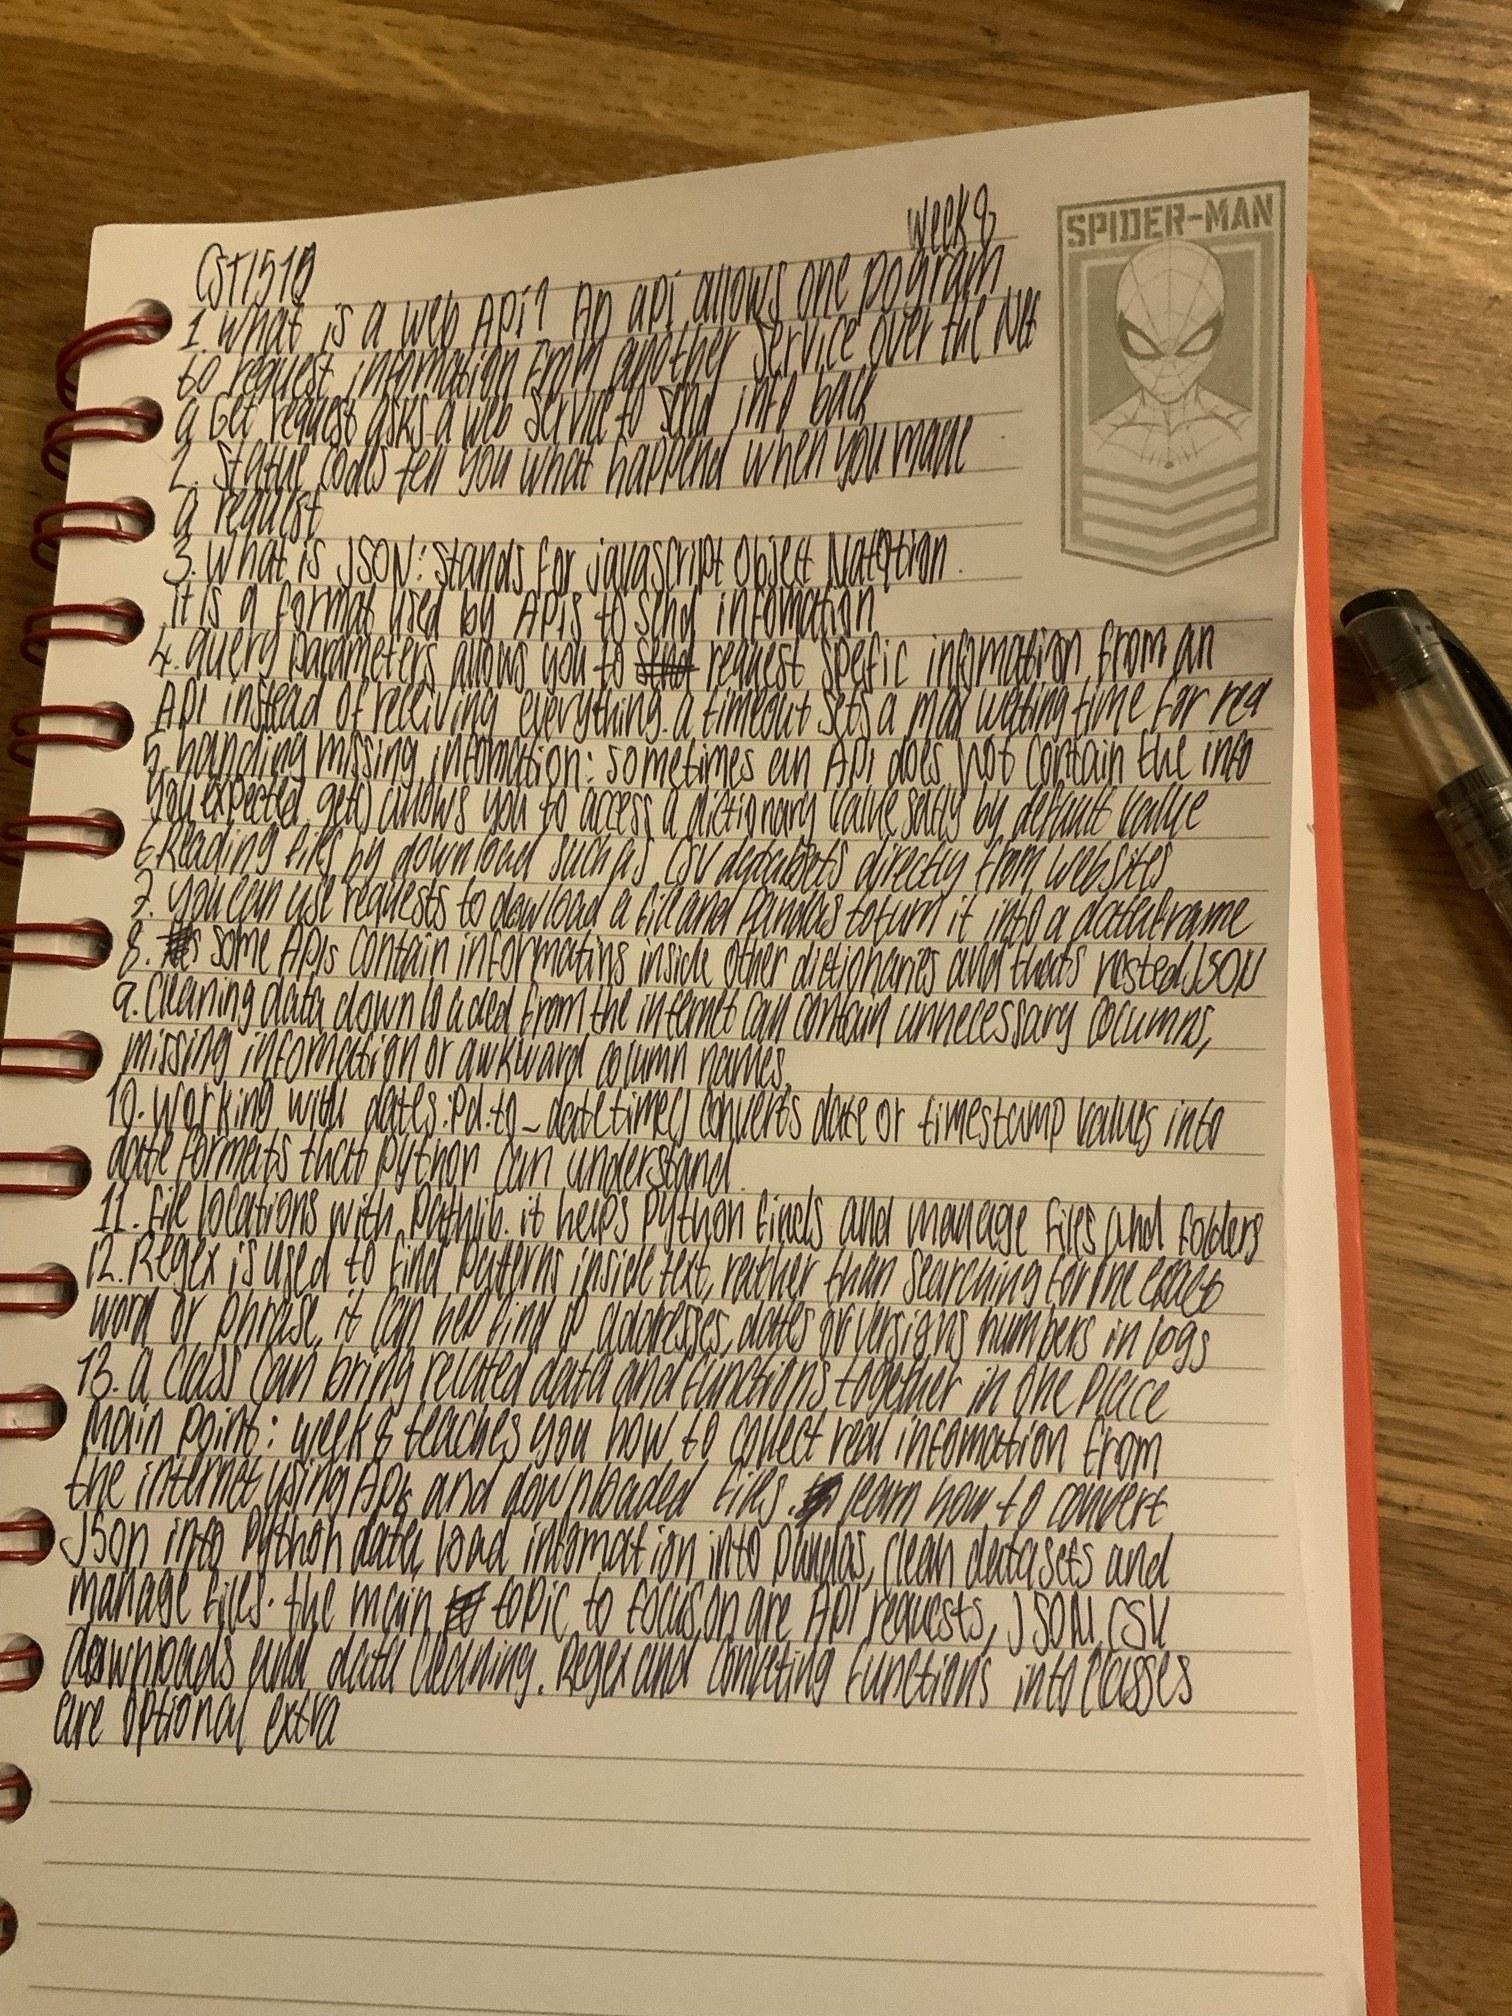